# **Assignment 3: PASCAL VOC 2007 Object Detection**

# ELEC5304 Project 3

**Group 45**

Name: Jinhao Zheng SID:540881594

Name: Yilin Wu   SID:550090241

Name: Huiwen Zhang SID:540319503

Name: Yiqian Guo  SID:550191940

Name: Chengnan Zhu SID:541029432


**Note**: This code was debugged and run on Colab

In this project, we use the PASCAL VOC 2007 dataset for **object detection**.

The dataset has been divided into training, validation, and test sets using the official VOC split files.

Students should use:
- train.txt for training
- val.txt for validation
- test.txt for final testing



The images are stored in JPEGImages.

The object detection annotations are stored in Annotations.

Each annotation file is an XML file that contains object class names and bounding-box coordinates.

**The code below prepares the dataset for this assignment.**

Please run the following code cells before starting your implementation.

### **1. Download and extract the dataset**


In [1]:
!wget -q http://host.robots.ox.ac.uk/pascal/VOC/voc2007/VOCtrainval_06-Nov-2007.tar
!wget -q http://host.robots.ox.ac.uk/pascal/VOC/voc2007/VOCtest_06-Nov-2007.tar

# Extract files
!tar -xf VOCtrainval_06-Nov-2007.tar
!tar -xf VOCtest_06-Nov-2007.tar

### **2. Check the dataset structure**

In [2]:
# Check the main VOC2007 folder

!ls VOCdevkit/VOC2007

Annotations  ImageSets	JPEGImages  SegmentationClass  SegmentationObject


##### **For this object detection project, we mainly use:**


*   JPEGImages         # image files
*   Annotations         # XML annotation files with bounding boxes
*   ImageSets/Main       # train/validation/test split files

### **3. Define dataset paths**

In [3]:
import os

VOC_ROOT = "VOCdevkit/VOC2007"

IMAGE_DIR = os.path.join(VOC_ROOT, "JPEGImages")
ANNOTATION_DIR = os.path.join(VOC_ROOT, "Annotations")
SPLIT_DIR = os.path.join(VOC_ROOT, "ImageSets", "Main")

print("Image folder:", IMAGE_DIR)
print("Annotation folder:", ANNOTATION_DIR)
print("Split folder:", SPLIT_DIR)

Image folder: VOCdevkit/VOC2007/JPEGImages
Annotation folder: VOCdevkit/VOC2007/Annotations
Split folder: VOCdevkit/VOC2007/ImageSets/Main


###**4. Load train, validation, and test image IDs**

PASCAL VOC provides official split files.
Each line is an image ID, such as 000005, which corresponds to:


*   JPEGImages/000005.jpg
*   Annotations/000005.xml

In [4]:
def load_image_ids(split_name):
    split_file = os.path.join(SPLIT_DIR, f"{split_name}.txt")

    with open(split_file, "r") as f:
        image_ids = [line.strip() for line in f.readlines()]

    return image_ids


train_ids = load_image_ids("train")
val_ids = load_image_ids("val")
test_ids = load_image_ids("test")

print("Number of training images:", len(train_ids))
print("Number of validation images:", len(val_ids))
print("Number of test images:", len(test_ids))

Number of training images: 2501
Number of validation images: 2510
Number of test images: 4952


### **5. Define VOC classes**





In [5]:
VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

print("Number of classes:", len(VOC_CLASSES))
print(VOC_CLASSES)

Number of classes: 20
['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']


### **6. Read XML annotation**

In [6]:
import xml.etree.ElementTree as ET

def read_voc_annotation(image_id):
    """
    Read annotation information for one image.

    Returns:
        objects: a list of dictionaries.
        Each dictionary contains class name and bounding box.
    """

    xml_path = os.path.join(ANNOTATION_DIR, image_id + ".xml")

    tree = ET.parse(xml_path)
    root = tree.getroot()

    objects = []

    for obj in root.findall("object"):
        class_name = obj.find("name").text

        bndbox = obj.find("bndbox")
        xmin = int(float(bndbox.find("xmin").text))
        ymin = int(float(bndbox.find("ymin").text))
        xmax = int(float(bndbox.find("xmax").text))
        ymax = int(float(bndbox.find("ymax").text))

        objects.append({
            "class_name": class_name,
            "bbox": [xmin, ymin, xmax, ymax]
        })

    return objects

### **7. Print one sample annotation**

In [7]:
sample_id = train_ids[0]

print("Image ID:", sample_id)
print("Image path:", os.path.join(IMAGE_DIR, sample_id + ".jpg"))
print("Annotation path:", os.path.join(ANNOTATION_DIR, sample_id + ".xml"))

objects = read_voc_annotation(sample_id)

print("Objects:")
for obj in objects:
    print(obj)

Image ID: 000012
Image path: VOCdevkit/VOC2007/JPEGImages/000012.jpg
Annotation path: VOCdevkit/VOC2007/Annotations/000012.xml
Objects:
{'class_name': 'car', 'bbox': [156, 97, 351, 270]}


### **8. Visualize two samples with bounding boxes**

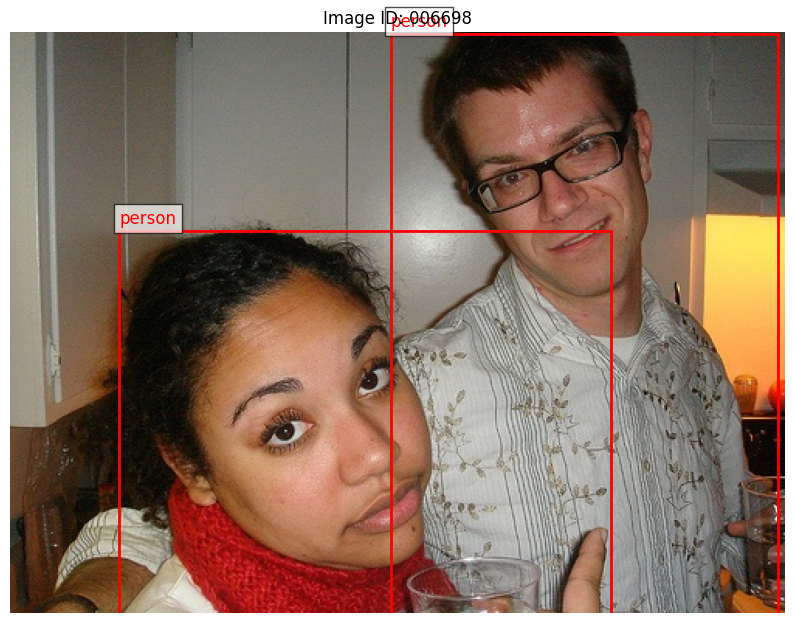

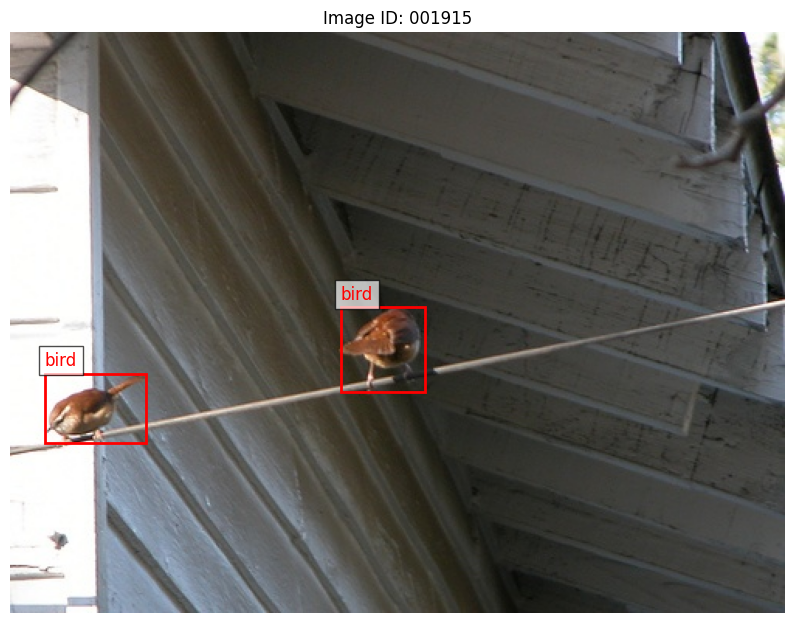

In [8]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

def visualize_sample(image_id):
    """
    Visualize one image with ground-truth bounding boxes.
    """

    image_path = os.path.join(IMAGE_DIR, image_id + ".jpg")
    image = Image.open(image_path).convert("RGB")

    objects = read_voc_annotation(image_id)

    fig, ax = plt.subplots(1, figsize=(10, 8))
    ax.imshow(image)

    for obj in objects:
        class_name = obj["class_name"]
        xmin, ymin, xmax, ymax = obj["bbox"]

        width = xmax - xmin
        height = ymax - ymin

        rect = patches.Rectangle(
            (xmin, ymin),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            xmin,
            ymin - 5,
            class_name,
            fontsize=12,
            color="red",
            bbox=dict(facecolor="white", alpha=0.7)
        )

    ax.set_title(f"Image ID: {image_id}")
    ax.axis("off")
    plt.show()


# Visualize two random training samples
sample_ids = random.sample(train_ids, 2)

for image_id in sample_ids:
    visualize_sample(image_id)

If the code runs correctly, two example images will be displayed with their bounding boxes and class labels.

## **Task 1: Object Detection Network Design**

In this task, you are required to design and train an object detection network using the PASCAL VOC 2007 dataset. The objective is to detect objects in images and predict both their class labels and bounding boxes.

You may build your model based on any suitable object detection architecture, such as YOLO, SSD, Faster R-CNN, RetinaNet, or other related models. You are also allowed to use or refer to existing architectures and open-source implementations. However, directly using an unchanged pre-trained model or simply running an official tutorial is not sufficient.

You must customize the model architecture and/or training pipeline to make it suitable for this assignment task. Possible customization may include, but is not limited to, modifying the backbone network, changing the detection head, adjusting anchor settings, freezing or unfreezing different layers, or designing other reasonable improvements.

The model performance should be evaluated using mAP@0.5 on the test set. A model achieving mAP@0.5 ≥ 60% will be considered to have met the performance requirement.

You should clearly explain your model design, training strategy, customization, and evaluation results in your (this) report. Your mark will not be determined by mAP alone. The correctness of the implementation, justification of the design choices, result visualization, and error analysis will also be considered.

### **Task 1 Solution: Faster R-CNN Detector**

We use Faster R-CNN with a MobileNetV3-FPN backbone because it provides a good balance between detection accuracy, computational efficiency, and implementation clarity. The MobileNetV3-FPN backbone helps reduce computational cost while still benefiting from multi-scale feature extraction, which is useful for detecting objects of different sizes in the PASCAL VOC 2007 dataset.

Faster R-CNN is a two-stage object detector. In the first stage, the Region Proposal Network generates candidate object regions. In the second stage, the ROI head classifies each proposed region and refines its bounding box. This two-stage structure is suitable for this assignment because it provides a clear and interpretable detection pipeline, making it easier to explain model behaviour, training strategy, and detection errors.

The detector is customised for VOC in four ways:

- The COCO detection head is replaced with a VOC-specific head for **20 classes + background**.
- The anchor sizes are reduced to 0.75 to better match small and medium VOC objects.
- Only the later backbone layers are fine-tuned with `trainable_backbone_layers=3`, which keeps general low-level features and adapts higher-level features to VOC.
- The ROI sampler is adjusted with a smaller batch (256) and higher positive fraction (0.4) to make training efficient on this dataset.

Although YOLO and SSD are generally faster during inference, they may be less suitable when the primary objective is to demonstrate a clear detection pipeline and achieve reliable mAP performance. Faster R-CNN allows the training process and model components to be customised more explicitly.

In [9]:
# import library
import time
from collections import defaultdict

import numpy as np
import pandas as pd

import torch
import torchvision

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import box_iou

from torchvision.models.detection import FasterRCNN_MobileNet_V3_Large_FPN_Weights # Faster R-CNN with a MobileNetV3-FPN backbone

In [10]:
# set seed
SEED = 5304
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [11]:
# VOC label mapping and detection dataset
CLASS_TO_IDX = {name: i + 1 for i, name in enumerate(VOC_CLASSES)}
IDX_TO_CLASS = {i + 1: name for i, name in enumerate(VOC_CLASSES)}
NUM_CLASSES = len(VOC_CLASSES) + 1 # 20 VOC classes + background


def VOC_target(image_id):
    objects = read_voc_annotation(image_id)

    boxes = []
    labels = []

    for obj in objects:
        class_name = obj["class_name"]
        if class_name not in CLASS_TO_IDX:
            continue

        boxes.append(obj["bbox"])
        labels.append(CLASS_TO_IDX[class_name])

    boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
    labels = torch.as_tensor(labels, dtype=torch.int64)
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])

    return {
        "boxes": boxes,
        "labels": labels,
        "image_id": torch.tensor([int(image_id)], dtype=torch.int64),
        "area": area,
        "iscrowd": torch.zeros((len(labels),), dtype=torch.int64),

        "difficult": torch.zeros((len(labels),), dtype=torch.int64),
    }


class VOCDetection(Dataset):
    def __init__(self, image_ids):
        self.image_ids = list(image_ids)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image = Image.open(os.path.join(IMAGE_DIR, image_id + ".jpg")).convert("RGB")

        return TF.to_tensor(image), VOC_target(image_id)

In [12]:
# Data loader
def collate_fn(batch):
    return tuple(zip(*batch))

BATCH_SIZE = 2
NUM_WORKERS = 2

train_loader = DataLoader(VOCDetection(train_ids), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, collate_fn=collate_fn)
val_loader = DataLoader(VOCDetection(val_ids), batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, collate_fn=collate_fn)
test_loader = DataLoader(VOCDetection(test_ids), batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, collate_fn=collate_fn)

In [13]:
# Faster R-CNN model with MobileNetV3-FPN and optimizer
def Faster_RCNN():
    weights = FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT

    # Backbone and COCO pretrained weights
    model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_fpn(
          weights=weights,
          trainable_backbone_layers=3,
          box_score_thresh=0.05,
          )

    # Replace the COCO prediction head with a VOC-specific head
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

    # RPN anchor size
    old_sizes = model.rpn.anchor_generator.sizes
    old_ratios = model.rpn.anchor_generator.aspect_ratios

    voc_sizes = tuple(tuple(max(8, int(round(size * 0.75))) for size in level) for level in old_sizes)

    model.rpn.anchor_generator = AnchorGenerator(sizes=voc_sizes, aspect_ratios=old_ratios)

    # ROI sample
    model.roi_heads.batch_size_per_image = 256
    model.roi_heads.positive_fraction = 0.4

    return model


model = Faster_RCNN().to(DEVICE)
optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                            lr=0.005, momentum=0.9, weight_decay=0.0005)

lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 194MB/s]


### **Model Discussion**

The model uses transfer learning from a COCO-pretrained Faster R-CNN detector, but it is adapted to PASCAL VOC by replacing the prediction head, adjusting anchors, and fine-tuning only selected backbone layers. This keeps training practical in Colab while still customizing the detector for the 20 VOC classes.
Training uses SGD with momentum and weight decay, a StepLR scheduler, and validation mAP@0.5 for checkpoint selection. The final test evaluation is only performed after loading the best validation checkpoint.


In [14]:
# Training loop
def to_device(images, targets):
    images = [image.to(DEVICE) for image in images]
    targets = [{k: v.to(DEVICE) for k, v in target.items()} for target in targets]
    return images, targets


def train(epoch):
    model.train()
    running_loss = 0.0
    start = time.time()

    for step, (images, targets) in enumerate(train_loader, start=1):
        images, targets = to_device(images, targets)
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        running_loss += float(loss.detach().cpu())

    print(f"Epoch {epoch} finished in {(time.time() - start):.1f} s")
    return running_loss / len(train_loader)

In [15]:
# mAP@0.5
def VOC_AP(recalls, precisions):
    recalls = np.r_[0.0, recalls, 1.0]
    precisions = np.r_[0.0, precisions, 0.0]

    for i in range(len(precisions) - 2, -1, -1):
        precisions[i] = max(precisions[i], precisions[i + 1])
    points = np.where(recalls[1:] != recalls[:-1])[0]

    return float(np.sum((recalls[points + 1] - recalls[points]) * precisions[points + 1]))


def Class_AP(predictions, targets, class_idx, iou_threshold=0.5):
    gt_by_image, detections, num_positive = {}, [], 0

    for image_idx, target in enumerate(targets):
        mask = target["labels"] == class_idx
        boxes = target["boxes"][mask]

        difficult = torch.zeros(len(boxes), dtype=torch.bool)

        gt_by_image[image_idx] = {
            "boxes": boxes,
            "difficult": difficult,
            "matched": torch.zeros(len(boxes), dtype=torch.bool),
        }
        num_positive += int((~difficult).sum())

    for image_idx, pred in enumerate(predictions):
        mask = pred["labels"] == class_idx
        for box, score in zip(pred["boxes"][mask], pred["scores"][mask]):
            detections.append((image_idx, float(score), box))

    if num_positive == 0:
        return np.nan, 0, len(detections)
    if len(detections) == 0:
        return 0.0, num_positive, 0

    detections.sort(key=lambda item: item[1], reverse=True)
    tp = np.zeros(len(detections), dtype=np.float32)
    fp = np.zeros(len(detections), dtype=np.float32)
    ignored = np.zeros(len(detections), dtype=bool)

    for det_idx, (image_idx, _, pred_box) in enumerate(detections):
        gt = gt_by_image[image_idx]

        if len(gt["boxes"]) == 0:
            fp[det_idx] = 1
            continue

        ious = box_iou(pred_box.unsqueeze(0), gt["boxes"]).squeeze(0)
        best_iou, best_gt_idx = torch.max(ious, dim=0)
        best_gt_idx = int(best_gt_idx)

        if float(best_iou) < iou_threshold:
            fp[det_idx] = 1
        elif bool(gt["difficult"][best_gt_idx]):
            ignored[det_idx] = True
        elif not bool(gt["matched"][best_gt_idx]):
            tp[det_idx] = 1
            gt["matched"][best_gt_idx] = True
        else:
            fp[det_idx] = 1

    keep = ~ignored
    tp = tp[keep]
    fp = fp[keep]

    if len(tp) == 0:
        return 0.0, num_positive, len(detections)

    recalls = np.cumsum(tp) / max(1, num_positive)
    precisions = np.cumsum(tp) / np.maximum(np.cumsum(tp) + np.cumsum(fp), 1e-8)

    return VOC_AP(recalls, precisions), num_positive, len(detections)

In [16]:
# Evaluation on validation or test set
@torch.no_grad()
def evaluate(data_loader, iou_threshold=0.5):
    model.eval()
    predictions, targets = [], []

    for images, batch_targets in data_loader:
        outputs = model([image.to(DEVICE) for image in images])
        predictions += [{k: v.detach().cpu() for k, v in output.items()} for output in outputs]
        targets += [{k: v.detach().cpu() for k, v in target.items()} for target in batch_targets]

    class_ap = {}
    for class_idx, class_name in IDX_TO_CLASS.items():
        ap, num_gt, num_det = Class_AP(predictions, targets, class_idx, iou_threshold)
        class_ap[class_name] = {"AP@0.5": ap, "num_gt": num_gt, "num_det": num_det}

    valid_aps = [row["AP@0.5"] for row in class_ap.values() if not np.isnan(row["AP@0.5"])]
    return {
        "mAP@0.5": float(np.mean(valid_aps)),
        "class_ap": class_ap,
        "predictions": predictions,
        "targets": targets,
    }

In [17]:
# Training, validation checkpoint selection, and final test evaluation
EPOCHS = 6
BEST_MODEL_PATH = "voc_fasterrcnn_mobilenetv3_fpn_custom.pth"
history, best_val_map = [], -1.0

for epoch in range(1, EPOCHS + 1):
    train_loss = train(epoch)
    lr_scheduler.step()

    val_results = evaluate(val_loader)
    val_map = val_results["mAP@0.5"]

    history.append({"epoch": epoch, "train_loss": train_loss, "val_mAP@0.5": val_map})
    print(f"Epoch {epoch}: train_loss={train_loss:.4f}, val_mAP@0.5={val_map:.4f}")

    if val_map > best_val_map:
        best_val_map = val_map
        torch.save(model.state_dict(), BEST_MODEL_PATH)

history_df = pd.DataFrame(history)
display(history_df)

# Load the best validation checkpoint before final test evaluation
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
test_results = evaluate(test_loader)

print(f"Final test mAP@0.5: {test_results['mAP@0.5']:.4f}")

Epoch 1 finished in 152.1 s
Epoch 1: train_loss=0.8690, val_mAP@0.5=0.6259
Epoch 2 finished in 152.5 s
Epoch 2: train_loss=0.6676, val_mAP@0.5=0.6631
Epoch 3 finished in 149.2 s
Epoch 3: train_loss=0.5974, val_mAP@0.5=0.6418
Epoch 4 finished in 143.4 s
Epoch 4: train_loss=0.4764, val_mAP@0.5=0.7222
Epoch 5 finished in 138.6 s
Epoch 5: train_loss=0.4750, val_mAP@0.5=0.7215
Epoch 6 finished in 137.1 s
Epoch 6: train_loss=0.4661, val_mAP@0.5=0.7244


,epoch,train_loss,val_mAP@0.5
0,1,0.868985,0.625870
1,2,0.667608,0.663052
2,3,0.597414,0.641768
3,4,0.476402,0.722151
4,5,0.474973,0.721480
5,6,0.466121,0.724380


Final test mAP@0.5: 0.7211


The final model achieved a test mAP@0.5 above 72%, which satisfies the required 60% threshold. Therefore, the training was stopped after 6 epochs because the model had already met the performance requirement while keeping the training cost reasonable.

## **Task 2: Detection Performance and Error Analysis**

Based on the object detection model developed in Task 1, you are required to conduct a detailed performance and error analysis to better understand the behaviour of your model.

Your analysis should include the following components:

1. Class-wise performance analysis

Report the AP or other appropriate detection performance metric for each object category. Identify which classes achieve better performance and which classes are more difficult for your model to detect.

2. Error case visualization

Visualize at least five representative failure cases from your detection results. Each example should clearly show the input image, ground-truth bounding boxes, predicted bounding boxes, predicted class labels, and confidence scores where applicable.

3. Error type discussion and potential solutions

Discuss the possible causes of the observed detection errors, such as missed detections, false positives, inaccurate bounding boxes, class confusion, small objects, occlusion, complex backgrounds, or class imbalance. You should also discuss possible solutions or improvements.

### **Task 2 Solution: Detection Performance and Error Analysis**

This section uses the test predictions obtained from the trained model in Task 1. It reports AP@0.5 for every VOC class, identifies strong and weak categories, visualizes five representative failure cases, and finally analyses the error types and discusses possible improvements.

In [18]:
# 1.Class-wise performance analysis
class_ap_table = pd.DataFrame.from_dict(test_results["class_ap"], orient="index").reset_index()
class_ap_table = class_ap_table.rename(columns={"index": "class"})
class_ap_table = class_ap_table.sort_values("AP@0.5", ascending=False).reset_index(drop=True)

valid_table = class_ap_table[class_ap_table["num_gt"] > 0]

# Report the AP for each object category.
display(valid_table[["class", "AP@0.5", "num_gt"]])

,class,AP@0.5,num_gt
0,train,0.871623,302
1,horse,0.851639,395
2,cat,0.836711,370
3,person,0.819530,5227
4,motorbike,0.814609,369
5,car,0.809162,1541
6,bicycle,0.804113,389
7,dog,0.793626,530
8,cow,0.789962,329
9,bus,0.779435,254


In [19]:
#Identify better and more difficult classes.
print("Five Better performing classes:")
display(valid_table.nlargest(5, "AP@0.5")[["class", "AP@0.5"]])

print("Five Most difficult classes:")
display(valid_table.nsmallest(5, "AP@0.5")[["class", "AP@0.5"]])

Five Better performing classes:


,class,AP@0.5
0,train,0.871623
1,horse,0.851639
2,cat,0.836711
3,person,0.819530
4,motorbike,0.814609


Five Most difficult classes:


,class,AP@0.5
19,pottedplant,0.460605
18,bottle,0.518119
17,chair,0.526148
16,boat,0.551507
15,diningtable,0.642064


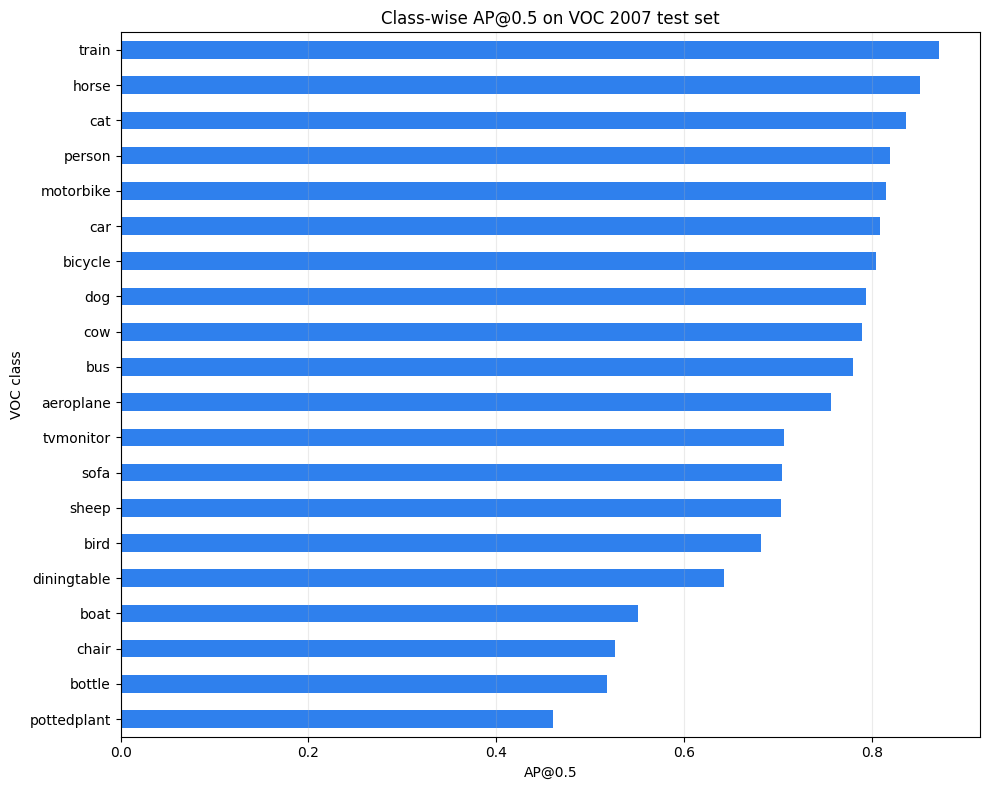

In [20]:
# Plot class-wise AP
ax = valid_table.sort_values("AP@0.5").plot(
    x="class", y="AP@0.5", kind="barh", figsize=(10, 8),
    legend=False, color="#2f80ed"
)
ax.set_xlabel("AP@0.5")
ax.set_ylabel("VOC class")
ax.set_title("Class-wise AP@0.5 on VOC 2007 test set")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [21]:
# 2. Error case visualization from five most difficult classes
SCORE_THRESHOLD = 0.5
IOU_THRESHOLD = 0.5

worst_classes = (
    class_ap_table[class_ap_table["num_gt"] > 0]
    .sort_values("AP@0.5")
    .head(5)["class"]
    .tolist()
)

error_cases = []

for class_name in worst_classes:
    class_id = CLASS_TO_IDX[class_name]

    for pred, target in zip(test_results["predictions"], test_results["targets"]):
        gt_mask = target["labels"] == class_id

        # Skip images that do not contain this class to visualize clearly.
        if gt_mask.sum() == 0:
            continue

        keep = pred["scores"] >= SCORE_THRESHOLD
        pred_boxes = pred["boxes"][keep]
        pred_labels = pred["labels"][keep]

        gt_boxes = target["boxes"][gt_mask]
        pred_class_boxes = pred_boxes[pred_labels == class_id]

        # Error case 1: error prediction
        is_error = len(pred_class_boxes) == 0

        # Error case 2: predictions exist, but none match the GT with IoU >= 0.5.
        if len(pred_class_boxes) > 0:
            ious = box_iou(pred_class_boxes, gt_boxes)
            is_error = float(ious.max()) < IOU_THRESHOLD

        if is_error:
            image_id = f"{int(target['image_id'].item()):06d}"
            error_cases.append({
                "image_id": image_id,
                "class_name": class_name,
                "target": target,
                "prediction": pred,
            })
            break

print("Selected error cases:")
for case in error_cases:
    print(case["class_name"], case["image_id"])

Selected error cases:
pottedplant 000196
bottle 000151
chair 000003
boat 000240
diningtable 000126


In [22]:
# Visualize selected error cases
import matplotlib.patches as patches

def label_name(label):
    return IDX_TO_CLASS.get(int(label), "background")


def draw_box(ax, box, text, color, linestyle="-"):
    xmin, ymin, xmax, ymax = [float(v) for v in box]

    ax.add_patch(
        patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            edgecolor=color,
            linewidth=2,
            linestyle=linestyle,
        )
    )

    ax.text(
        xmin,
        max(0, ymin - 5),
        text,
        fontsize=8,
        color="black",
        bbox=dict(facecolor=color, alpha=0.7, edgecolor="none"),
    )

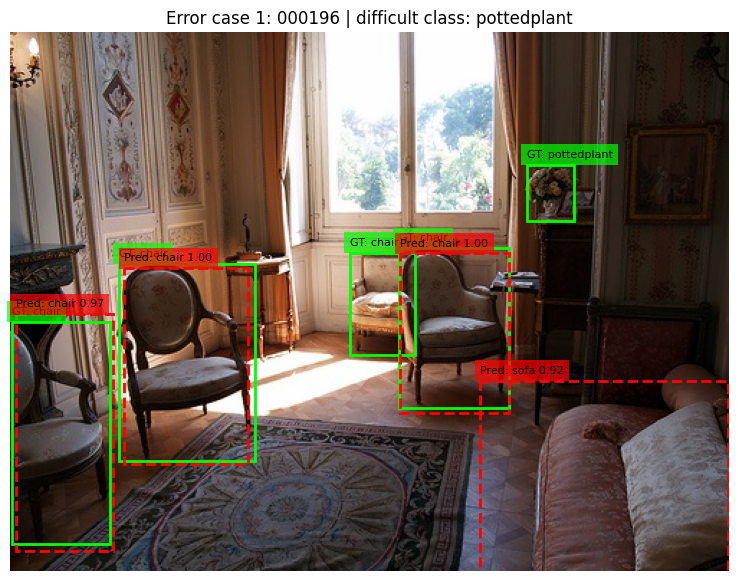

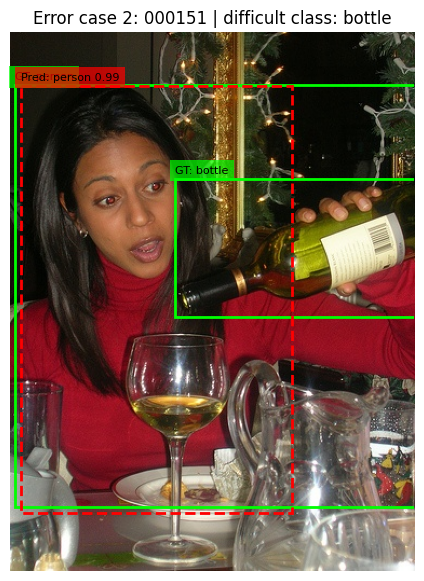

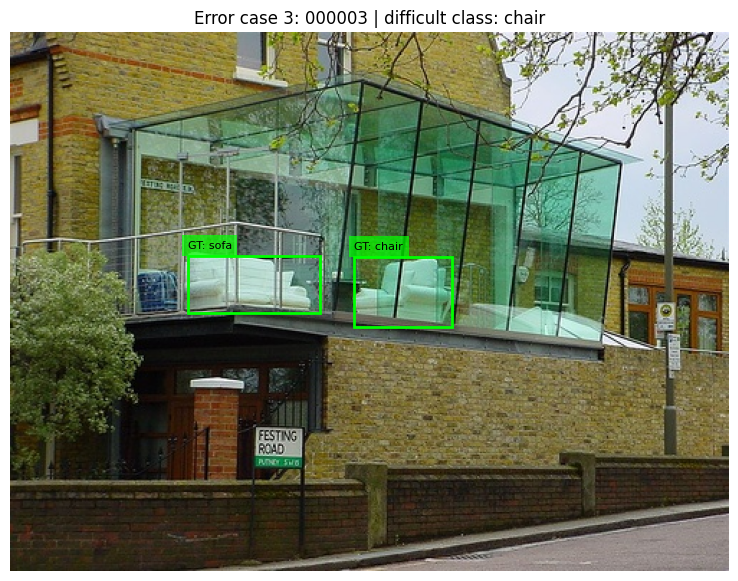

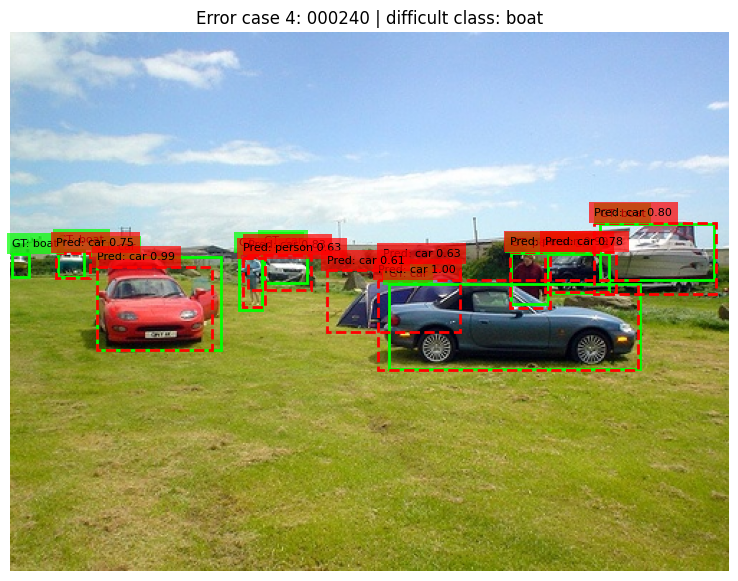

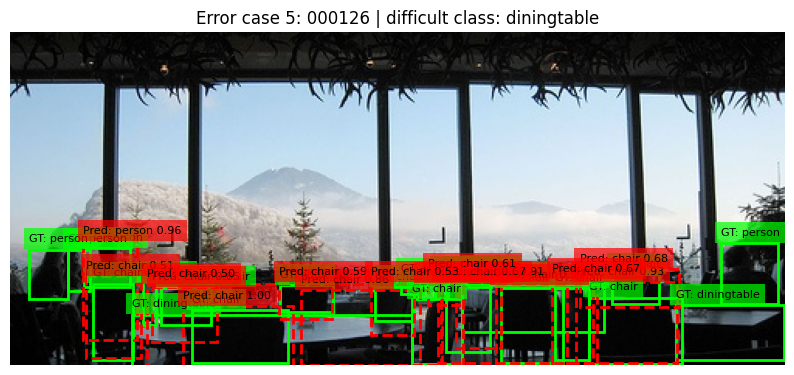

In [23]:
# Plot error case
for i, case in enumerate(error_cases, start=1):
    image_id = case["image_id"]
    target = case["target"]
    pred = case["prediction"]

    image = Image.open(os.path.join(IMAGE_DIR, image_id + ".jpg")).convert("RGB")

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(image)

    # Ground-truth boxes
    for box, label in zip(target["boxes"], target["labels"]):
        draw_box(
            ax,
            box,
            "GT: " + label_name(label),
            color="lime",
        )

    # Predicted boxes with confidence scores
    keep = pred["scores"] >= SCORE_THRESHOLD
    for box, label, score in zip(
        pred["boxes"][keep],
        pred["labels"][keep],
        pred["scores"][keep],
    ):
        draw_box(
            ax,
            box,
            f"Pred: {label_name(label)} {float(score):.2f}",
            color="red",
            linestyle="--",
        )

    ax.set_title(
        f"Error case {i}: {image_id} | difficult class: {case['class_name']}"
    )
    ax.axis("off")
    plt.show()

### Error Case Discussion

The following five failure cases were selected from the detection outputs of our trained model on the VOC 2007 test set. These examples are specific to this experiment, but they also reflect common object detection challenges, such as small objects, occlusion, cluttered backgrounds, and inaccurate localization.

| Case | Image ID | Target Class | Error Issue |
|---|---|---|---|
| 1 | 000196 | pottedplant | The pottedplant is small and difficult to distinguish from the background. |
| 2 | 000151 | bottle | The bottle blends into the background, making it difficult to detect clearly. |
| 3 | 000003 | chair | The indoor scene contains clutter and overlapping objects. |
| 4 | 000240 | boat | The boat is far away in the background, making it blurry and difficult to detect clearly. |
| 5 | 000126 | diningtable | Overlapping objects obscure part of the table boundary, making localization difficult. |

### 3. Error type discussion and potential solutions

The class-wise AP results show that the model performs better on visually distinctive and relatively large object categories. The best performing classes are train, horse, cat, person, car, and motorbike, with AP@0.5 values above 0.8. These objects usually have clearer shapes, stronger visual features, and are easier to separate from the background.

In contrast, the most difficult classes are pottedplant, chair, bottle, boat, and diningtable. Their AP@0.5 values are lower, especially pottedplant, chair, and bottle. These categories are more challenging because they are often small, partially occluded, or located in cluttered scenes. For example, bottles and potted plants usually occupy a small area in the image, while chairs and dining tables often appear in complex indoor environments with many overlapping objects.

The five visualized failure cases show several common error types. First, some objects are missed by the detector, especially when they are small, far from the camera, or partially blocked by other objects. Second, false positives occur when the model predicts an object in the background or on visually similar regions. Third, some predicted bounding boxes do not match the ground-truth boxes accurately, which indicates localization errors. Fourth, duplicate detections may appear when multiple predicted boxes cover the same object. Finally, class confusion can happen when two categories have similar shapes or appear in similar contexts.

These errors suggest that the model still has limitations in detecting small objects, handling occlusion, and separating target objects from complex backgrounds. The performance gap between strong and weak classes also indicates that the model may benefit from better feature representation and more balanced learning across categories.

Several improvements could be used in future work. First, the model could be trained for more epochs so that the detection head and backbone can adapt more fully to the VOC dataset. Second, stronger data augmentation, such as random crop, color jitter, horizontal flip, and scale augmentation, could improve robustness to object size, lighting, and viewpoint changes. Third, multi-scale training or using a larger input resolution could help the model detect small objects such as bottles and potted plants. Fourth, anchor sizes, confidence thresholds, and NMS thresholds could be further tuned using validation results to reduce missed detections, false positives, and duplicate boxes

Overall, the model achieved a reasonable detection performance, but the error analysis shows that small objects, occlusion, cluttered backgrounds, and localization accuracy are still the main challenges. The proposed improvements directly target these weaknesses and could further improve the mAP and class-wise detection performance.

**All code implementation, experimental results, and written discussion must be completed within this notebook.**

**Please save your final work as an .ipynb file and submit.**

## **Marking rubric**
The Assignment 3 is totally 50 marks.

**Report Submission — 25 marks.**

Task 1: Object Detection Network Design — 17 marks

(Model implementation:5, Model / training pipeline customization and discussion :10,Performance:2)

Task 2: Detection Performance and Error Analysis — 8 marks

(Class-wise performance analysis:3, Error case visualization and discussion:3, Potential solutions:2)



**Oral Question — 25 marks**

Each group will be asked some questions in week 13.
